In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Laptop.csv', encoding='latin1')

In [3]:
df

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target)
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


In [4]:
df.shape

(1303, 13)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   object 
 2   Product               1303 non-null   object 
 3   TypeName              1303 non-null   object 
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   object 
 6   Cpu                   1303 non-null   object 
 7   Ram                   1303 non-null   object 
 8   Memory                1303 non-null   object 
 9   Gpu                   1303 non-null   object 
 10  OpSys                 1303 non-null   object 
 11  Weight                1303 non-null   object 
 12  Price_euros (Target)  1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


# Data Cleaning Process:

In [6]:
df.duplicated().sum() #to ensure no duplicate row is present

0

In [7]:
df.isnull().sum()

laptop_ID               0
Company                 0
Product                 0
TypeName                0
Inches                  0
ScreenResolution        0
Cpu                     0
Ram                     0
Memory                  0
Gpu                     0
OpSys                   0
Weight                  0
Price_euros (Target)    0
dtype: int64

In [8]:
df['Ram'].str.replace('GB','') #removing GB from RAM column

0        8
1        8
2        8
3       16
4        8
        ..
1298     4
1299    16
1300     2
1301     6
1302     4
Name: Ram, Length: 1303, dtype: object

In [9]:
df['Weight'] = df['Weight'].str.replace('kg','') #removing kg from weight column

In [10]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target)
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60


In [11]:
# Handle missing values in 'Ram' before conversion
df['Ram'] = df['Ram'].astype(str).str.replace('GB', '')
df['Ram'] = pd.to_numeric(df['Ram'], errors='coerce').fillna(0).astype(int)

# Convert Weight to float
df['Weight'] = pd.to_numeric(df['Weight'], errors='coerce').fillna(0).astype(float)


In [12]:
print(df['Ram'].head())
print(df['Weight'].head())


0     8
1     8
2     8
3    16
4     8
Name: Ram, dtype: int32
0    1.37
1    1.34
2    1.86
3    1.83
4    1.37
Name: Weight, dtype: float64


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   object 
 2   Product               1303 non-null   object 
 3   TypeName              1303 non-null   object 
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   object 
 6   Cpu                   1303 non-null   object 
 7   Ram                   1303 non-null   int32  
 8   Memory                1303 non-null   object 
 9   Gpu                   1303 non-null   object 
 10  OpSys                 1303 non-null   object 
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
dtypes: float64(3), int32(1), int64(1), object(8)
memory usage: 127.4+ KB


C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1093788652.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Price_euros (Target)'])


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

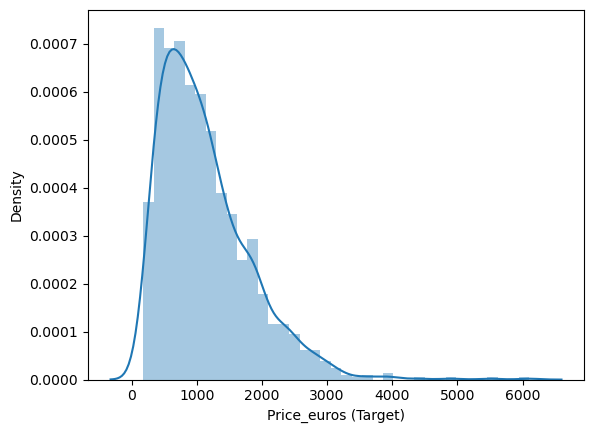

In [14]:
sns.distplot(df['Price_euros (Target)'])

<Axes: >

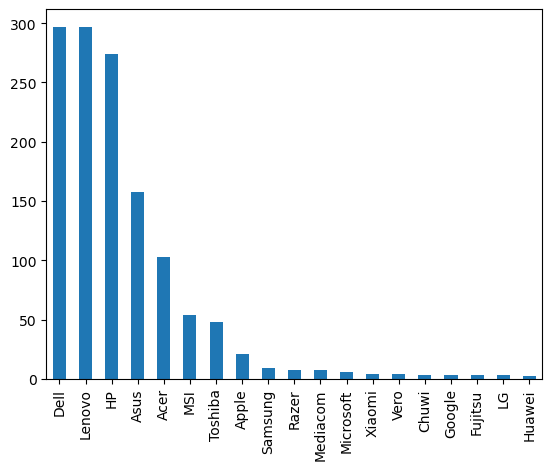

In [15]:
df['Company'].value_counts().plot(kind='bar')

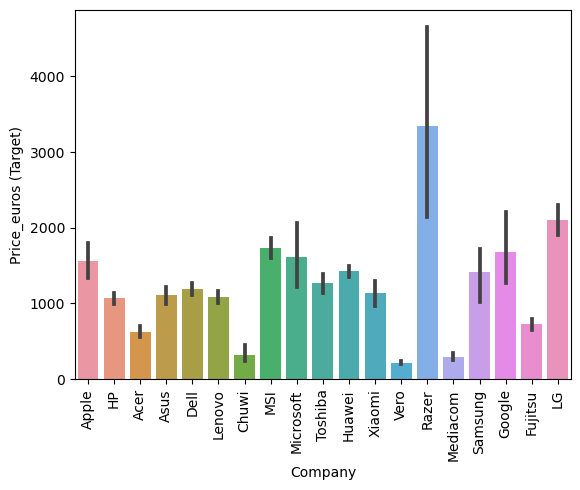

In [16]:
sns.barplot(x=df['Company'], y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')  # Rotate x-axis labels for better readability
plt.show()

<Axes: >

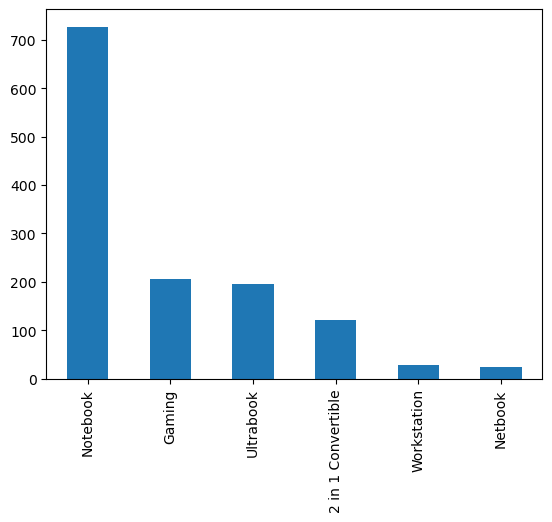

In [17]:
df['TypeName'].value_counts().plot(kind='bar')

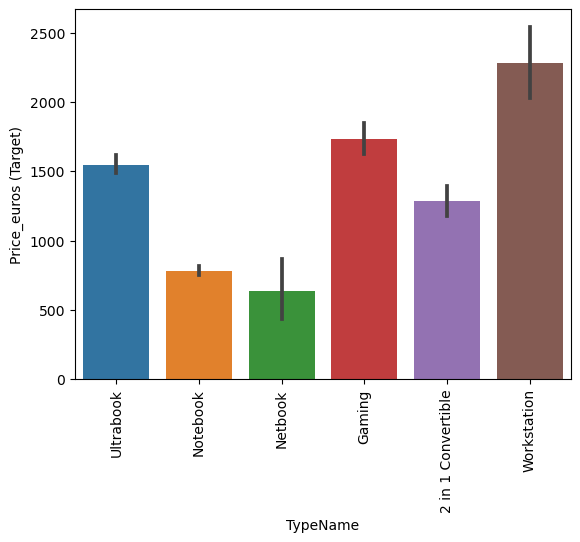

In [18]:
sns.barplot(x=df['TypeName'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

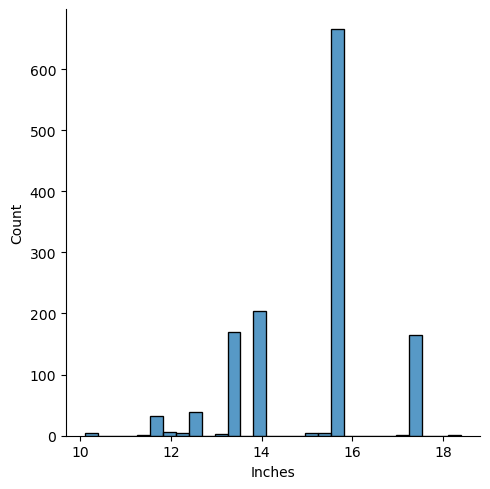

In [19]:
sns.displot(df['Inches'])

<Axes: xlabel='Inches', ylabel='Price_euros (Target)'>

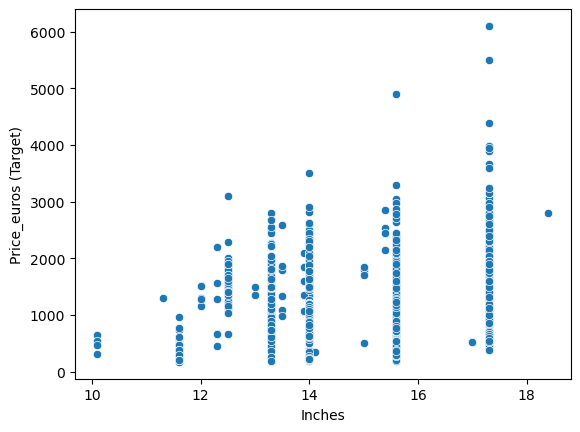

In [20]:
sns.scatterplot(x=df['Inches'],y=df['Price_euros (Target)'])

In [21]:
df['ScreenResolution'].value_counts()

Full HD 1920x1080                                507
1366x768                                         281
IPS Panel Full HD 1920x1080                      230
IPS Panel Full HD / Touchscreen 1920x1080         53
Full HD / Touchscreen 1920x1080                   47
1600x900                                          23
Touchscreen 1366x768                              16
Quad HD+ / Touchscreen 3200x1800                  15
IPS Panel 4K Ultra HD 3840x2160                   12
IPS Panel 4K Ultra HD / Touchscreen 3840x2160     11
4K Ultra HD / Touchscreen 3840x2160               10
4K Ultra HD 3840x2160                              7
Touchscreen 2560x1440                              7
IPS Panel 1366x768                                 7
IPS Panel Quad HD+ / Touchscreen 3200x1800         6
IPS Panel Retina Display 2560x1600                 6
IPS Panel Retina Display 2304x1440                 6
Touchscreen 2256x1504                              6
IPS Panel Touchscreen 2560x1440               

In [22]:
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)


In [23]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0


<Axes: >

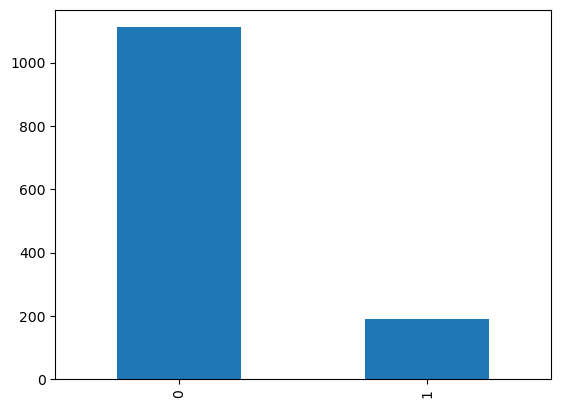

In [24]:
df['Touchscreen'].value_counts().plot(kind='bar')

<Axes: xlabel='Touchscreen', ylabel='Price_euros (Target)'>

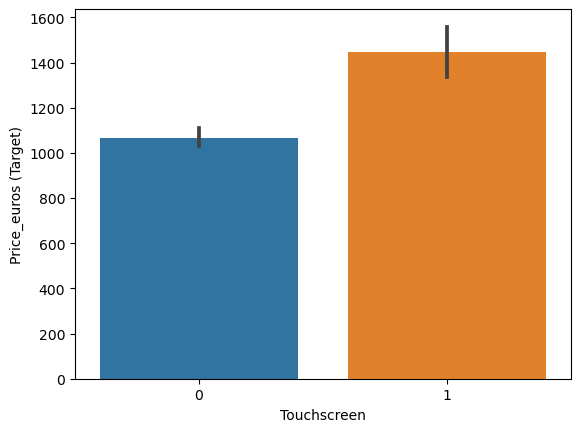

In [25]:
sns.barplot(x=df['Touchscreen'],y=df['Price_euros (Target)'])

In [26]:
df['Ips']=df['ScreenResolution'].apply(lambda x:1 if 'IPS' in x else 0)

<Axes: >

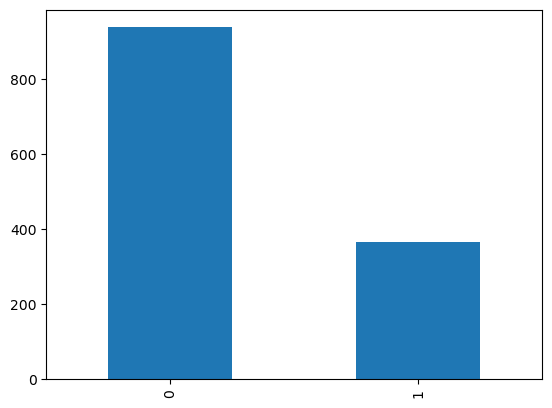

In [27]:
df['Ips'].value_counts().plot(kind='bar')

<Axes: xlabel='Ips', ylabel='Price_euros (Target)'>

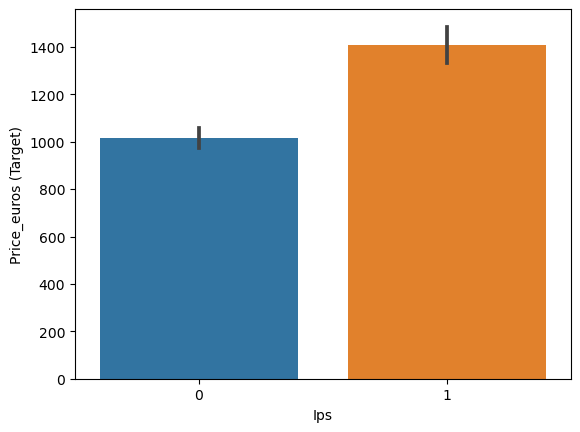

In [28]:
sns.barplot(x=df['Ips'],y=df['Price_euros (Target)'])

In [29]:
new=df['ScreenResolution'].str.split('x',n=1,expand=True)
new

,0,1
0,IPS Panel Retina Display 2560,1600
1,1440,900
2,Full HD 1920,1080
3,IPS Panel Retina Display 2880,1800
4,IPS Panel Retina Display 2560,1600
...,...,...
1298,IPS Panel Full HD / Touchscreen 1920,1080
1299,IPS Panel Quad HD+ / Touchscreen 3200,1800
1300,1366,768
1301,1366,768


In [30]:
df['X_res']=new[0]
df['Y_res']=new[1]

In [31]:
df.sample(5)

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res
389,395,Lenovo,ThinkPad X1,2 in 1 Convertible,14.0,Touchscreen 2560x1440,Intel Core i7 7500U 2.7GHz,16,512GB SSD,Intel HD Graphics 620,Windows 10,1.42,2509.0,1,0,Touchscreen 2560,1440
1109,1124,Asus,Rog GL552VW-CN470T,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,16,128GB SSD + 1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.59,1339.0,0,1,IPS Panel Full HD 1920,1080
1190,1208,Lenovo,Legion Y520-15IKBN,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8,1TB HDD,Nvidia GeForce GTX 1050,Windows 10,2.40,819.0,0,1,IPS Panel Full HD 1920,1080
893,904,Lenovo,ThinkPad T470s,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,Windows 10,1.32,1799.0,0,1,IPS Panel Full HD 1920,1080
1192,1210,HP,250 G6,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4,500GB HDD,Intel HD Graphics 620,Windows 10,1.86,485.0,0,0,1366,768


In [32]:
df['X_res']=df['X_res'].str.replace(',','').str.findall(r'(\d+\.?\d+)').apply(lambda 
                                                                              x:x[0])

In [33]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,2560,1600
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,1440,900
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,1920,1080
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,2880,1800
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,2560,1600


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   object 
 2   Product               1303 non-null   object 
 3   TypeName              1303 non-null   object 
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   object 
 6   Cpu                   1303 non-null   object 
 7   Ram                   1303 non-null   int32  
 8   Memory                1303 non-null   object 
 9   Gpu                   1303 non-null   object 
 10  OpSys                 1303 non-null   object 
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
 13  Touchscreen           1303 non-null   int64  
 14  Ips                   1303 non-null   int64  
 15  X_res                

In [35]:
df['X_res']=df['X_res'].astype('int')
df['Y_res']=df['Y_res'].astype('int')

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   object 
 2   Product               1303 non-null   object 
 3   TypeName              1303 non-null   object 
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   object 
 6   Cpu                   1303 non-null   object 
 7   Ram                   1303 non-null   int32  
 8   Memory                1303 non-null   object 
 9   Gpu                   1303 non-null   object 
 10  OpSys                 1303 non-null   object 
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
 13  Touchscreen           1303 non-null   int64  
 14  Ips                   1303 non-null   int64  
 15  X_res                

In [37]:
df.corr()['Price_euros (Target)']

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1672364737.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['Price_euros (Target)']


laptop_ID               0.067830
Inches                  0.068197
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
X_res                   0.556529
Y_res                   0.552809
Name: Price_euros (Target), dtype: float64

In [38]:
# Ensure the resolution and diagonal size columns exist
df['ppi'] = (((df['X_res']**2) + (df['Y_res']**2))**0.5) / df['Inches']
df['ppi'] = df['ppi'].astype('float')  # Ensure it's a float type


In [39]:
df.corr()['Price_euros (Target)']

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1672364737.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['Price_euros (Target)']


laptop_ID               0.067830
Inches                  0.068197
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
X_res                   0.556529
Y_res                   0.552809
ppi                     0.473487
Name: Price_euros (Target), dtype: float64

In [40]:
df.drop(columns=['ScreenResolution'],inplace=True)

In [41]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res,ppi
0,1,Apple,MacBook Pro,Ultrabook,13.3,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,2560,1600,226.983005
1,2,Apple,Macbook Air,Ultrabook,13.3,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,1440,900,127.677940
2,3,HP,250 G6,Notebook,15.6,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,1920,1080,141.211998
3,4,Apple,MacBook Pro,Ultrabook,15.4,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,2880,1800,220.534624
4,5,Apple,MacBook Pro,Ultrabook,13.3,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,2560,1600,226.983005


In [42]:
df.drop(columns=['Inches','X_res','Y_res'],inplace=True)

In [43]:
df.head()

,laptop_ID,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi
0,1,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005
1,2,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940
2,3,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998
3,4,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624
4,5,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005


In [44]:
df['Cpu'].value_counts()

Intel Core i5 7200U 2.5GHz       190
Intel Core i7 7700HQ 2.8GHz      146
Intel Core i7 7500U 2.7GHz       134
Intel Core i7 8550U 1.8GHz        73
Intel Core i5 8250U 1.6GHz        72
                                ... 
Intel Core M M3-6Y30 0.9GHz        1
AMD A9-Series 9420 2.9GHz          1
Intel Core i3 6006U 2.2GHz         1
AMD A6-Series 7310 2GHz            1
Intel Xeon E3-1535M v6 3.1GHz      1
Name: Cpu, Length: 118, dtype: int64

In [45]:
df['Cpu Name'] = df['Cpu'].apply(lambda x: ' '.join(x.split()[:3]))

df['Cpu Name']

0            Intel Core i5
1            Intel Core i5
2            Intel Core i5
3            Intel Core i7
4            Intel Core i5
               ...        
1298         Intel Core i7
1299         Intel Core i7
1300    Intel Celeron Dual
1301         Intel Core i7
1302    Intel Celeron Dual
Name: Cpu Name, Length: 1303, dtype: object

In [46]:
print(df['Cpu Name'].unique())
print(df['Cpu brand'].value_counts())


['Intel Core i5' 'Intel Core i7' 'AMD A9-Series 9420' 'Intel Core i3'
 'Intel Core M' 'Intel Atom x5-Z8350' 'AMD E-Series E2-9000e'
 'Intel Atom x5-Z8300' 'AMD E-Series E2-6110' 'AMD A6-Series 9220'
 'Intel Celeron Dual' 'AMD Ryzen 1700' 'Intel Pentium Quad'
 'Intel Atom x5-Z8550' 'AMD FX 9830P' 'AMD E-Series 6110'
 'Intel Xeon E3-1505M' 'AMD E-Series 9000e' 'AMD A10-Series A10-9620P'
 'AMD A6-Series A6-9220' 'AMD A10-Series 9600P' 'AMD A8-Series 7410'
 'AMD A12-Series 9720P' 'Intel Celeron Quad' 'AMD Ryzen 1600'
 'AMD A10-Series 9620P' 'AMD E-Series 7110' 'AMD A9-Series A9-9420'
 'Intel Xeon E3-1535M' 'AMD E-Series E2-9000' 'AMD A6-Series 7310'
 'Intel Atom Z8350' 'Intel Pentium Dual' 'AMD A12-Series 9700P'
 'AMD A4-Series 7210' 'AMD FX 8800P' 'Intel Atom X5-Z8350'
 'Samsung Cortex A72&A53' 'AMD E-Series 9000' 'AMD A9-Series 9410']


KeyError: 'Cpu brand'

In [48]:
def fetch_processor(text):
    if 'Intel Core i7' in text:
        return 'Intel Core i7'
    elif 'Intel Core i5' in text:
        return 'Intel Core i5'
    elif 'Intel Core i3' in text:
        return 'Intel Core i3'
    elif 'Intel' in text:
        return 'Other Intel Processor'
    else:
        return 'AMD Processor'


In [49]:
df['Cpu brand']=df['Cpu Name'].apply(fetch_processor)
df['Cpu brand']

0               Intel Core i5
1               Intel Core i5
2               Intel Core i5
3               Intel Core i7
4               Intel Core i5
                ...          
1298            Intel Core i7
1299            Intel Core i7
1300    Other Intel Processor
1301            Intel Core i7
1302    Other Intel Processor
Name: Cpu brand, Length: 1303, dtype: object

In [50]:
df.head()

,laptop_ID,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu Name,Cpu brand
0,1,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,Intel Core i5
1,2,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,Intel Core i5
2,3,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,Intel Core i5
3,4,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,Intel Core i7
4,5,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,Intel Core i5


<Axes: >

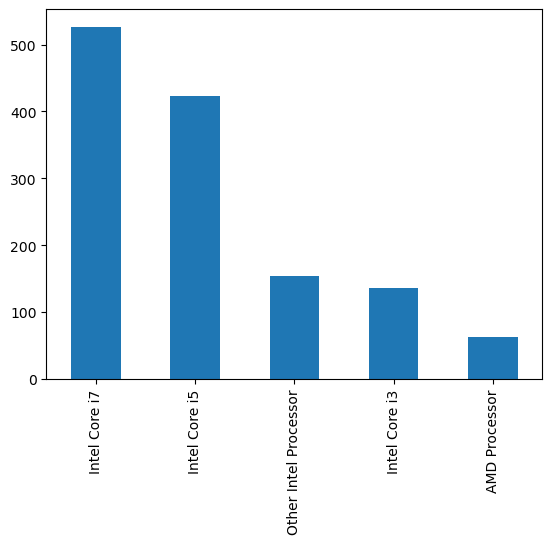

In [51]:
df['Cpu brand'].value_counts().plot(kind='bar')

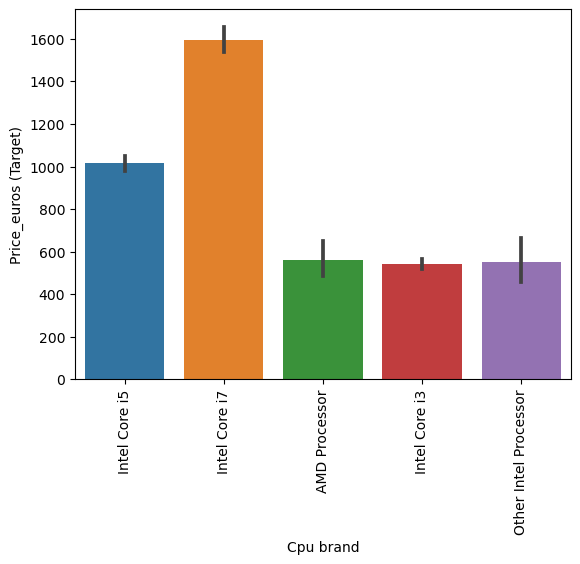

In [52]:
sns.barplot(x=df['Cpu brand'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [53]:
df.drop(columns=['Cpu', 'Cpu Name'], inplace=True)

In [54]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5
1,2,Apple,Macbook Air,Ultrabook,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5
2,3,HP,250 G6,Notebook,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5
3,4,Apple,MacBook Pro,Ultrabook,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7
4,5,Apple,MacBook Pro,Ultrabook,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5


<Axes: >

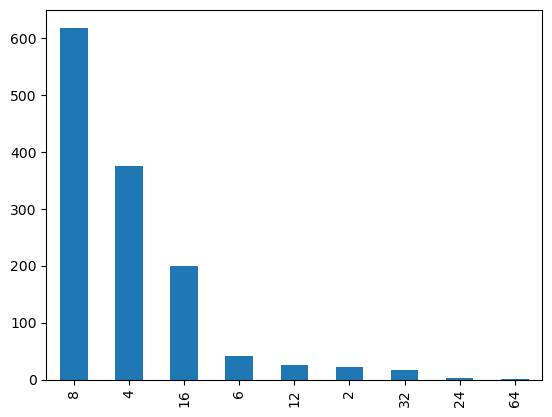

In [55]:
df['Ram'].value_counts().plot(kind='bar')

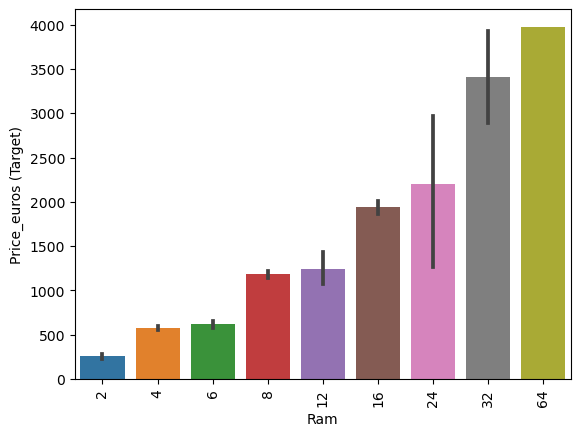

In [56]:
sns.barplot(x=df['Ram'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [57]:
df['Memory'].value_counts()

256GB SSD                        412
1TB HDD                          223
500GB HDD                        132
512GB SSD                        118
128GB SSD +  1TB HDD              94
128GB SSD                         76
256GB SSD +  1TB HDD              73
32GB Flash Storage                38
2TB HDD                           16
64GB Flash Storage                15
512GB SSD +  1TB HDD              14
1TB SSD                           14
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
512GB SSD +  2TB HDD               3
16GB SSD                           3
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
256GB SSD +  256GB SSD             2
512GB SSD +  256GB SSD             1
5

In [58]:
# Cleaning and processing the 'Memory' column
df['Memory'] = df['Memory'].astype(str).replace('\.0', '', regex=True)
df["Memory"] = df["Memory"].str.replace('GB', '')
df["Memory"] = df["Memory"].str.replace('TB', '000')

# Splitting the 'Memory' column into two parts
new = df["Memory"].str.split("+", n=1, expand=True)

# Assigning the parts to 'first' and 'second'
df["first"] = new[0].str.strip()
df["second"] = new[1]

# Creating layer flags based on 'first' column
df["Layer1HDD"] = df["first"].apply(lambda x: 1 if "HDD" in x else 0)
df["Layer1SSD"] = df["first"].apply(lambda x: 1 if "SSD" in x else 0)
df["Layer1Hybrid"] = df["first"].apply(lambda x: 1 if "Hybrid" in x else 0)
df["Layer1Flash_Storage"] = df["first"].apply(lambda x: 1 if "Flash Storage" in x else 0)

# Cleaning 'first' column to only retain digits
df['first'] = df['first'].str.replace(r'\D', '')

# Fill missing values in 'second' column with "0"
df["second"].fillna("0", inplace=True)

# Clean the 'second' column by removing non-numeric characters and leading/trailing spaces
df["second"] = df["second"].str.replace(r'\D', '', regex=True).str.strip()

# Convert both 'first' and 'second' columns to integers
df["first"] = df["first"].astype(int)
df["second"] = df["second"].astype(int)

# Calculating the storage types based only on the first layer (removing Layer2 logic)
df["HDD"] = df["first"] * df["Layer1HDD"]
df["SSD"] = df["first"] * df["Layer1SSD"]
df["Hybrid"] = df["first"] * df["Layer1Hybrid"]
df["Flash_Storage"] = df["first"] * df["Layer1Flash_Storage"]

# Dropping intermediate columns
df.drop(columns=['first', 'second', 'Layer1HDD', 'Layer1SSD', 'Layer1Hybrid',
                 'Layer1Flash_Storage'], inplace=True)


C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\2876624524.py:20: FutureWarning: The default value of regex will change from True to False in a future version.
  df['first'] = df['first'].str.replace(r'\D', '')


In [59]:
df.sample(5)

,laptop_ID,Company,Product,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Hybrid,Flash_Storage
81,83,Apple,"MacBook 12""",Ultrabook,8,512 SSD,Intel HD Graphics 615,macOS,0.92,1510.00,0,1,226.415547,Intel Core i5,0,512,0,0
120,123,Acer,Spin 3,Notebook,6,1000 HDD,Intel HD Graphics 620,Windows 10,2.10,479.00,1,1,141.211998,Intel Core i3,1000,0,0,0
985,999,Dell,Inspiron 3567,Notebook,4,500 HDD,AMD Radeon R5 M430,Windows 10,2.25,599.00,0,0,100.454670,Intel Core i5,500,0,0,0
537,544,HP,250 G6,Notebook,4,256 SSD,Intel HD Graphics 405,Windows 10,1.86,398.99,0,0,141.211998,Other Intel Processor,0,256,0,0
1291,1309,Acer,Aspire ES1-531,Notebook,4,500 HDD,Intel HD Graphics 400,Linux,2.40,289.00,0,0,100.454670,Other Intel Processor,500,0,0,0


In [60]:
df.drop(columns=['Memory'],inplace=True)

In [61]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Hybrid,Flash_Storage
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128,0,0
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,0,128
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,256,0,0
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512,0,0
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256,0,0


In [62]:
df.corr()['Price_euros (Target)']

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1672364737.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['Price_euros (Target)']


laptop_ID               0.067830
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
ppi                     0.473487
HDD                    -0.380428
SSD                     0.676202
Hybrid                 -0.040147
Flash_Storage          -0.040511
Name: Price_euros (Target), dtype: float64

In [63]:
df.drop(columns=['Hybrid','Flash_Storage'],inplace=True)

In [64]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,256
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256


In [65]:
df['Gpu'].value_counts()

Intel HD Graphics 620      281
Intel HD Graphics 520      185
Intel UHD Graphics 620      68
Nvidia GeForce GTX 1050     66
Nvidia GeForce GTX 1060     48
                          ... 
AMD Radeon R5 520            1
AMD Radeon R7                1
Intel HD Graphics 540        1
AMD Radeon 540               1
ARM Mali T860 MP4            1
Name: Gpu, Length: 110, dtype: int64

In [66]:
df['Gpu brand'] = df['Gpu'].apply(lambda x:x.split()[0])

In [67]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128,Intel
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,256,Intel
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512,AMD
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256,Intel


In [68]:
df['Gpu brand'].value_counts()

Intel     722
Nvidia    400
AMD       180
ARM         1
Name: Gpu brand, dtype: int64

In [69]:
df=df[df['Gpu brand']!='ARM']

In [70]:
df['Gpu brand'].value_counts()

Intel     722
Nvidia    400
AMD       180
Name: Gpu brand, dtype: int64

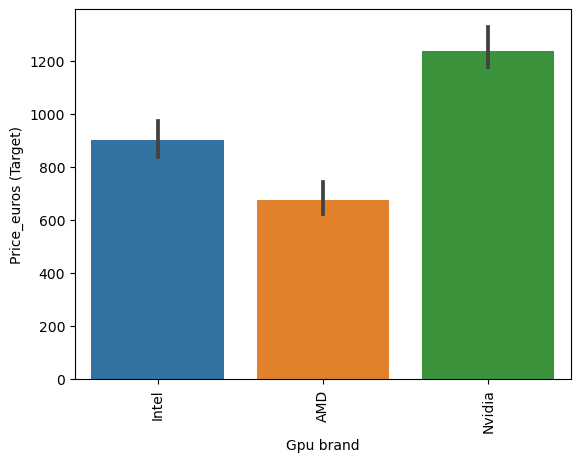

In [71]:
sns.barplot(x=df['Gpu brand'],y=df['Price_euros (Target)'],estimator=np.median)
plt.xticks(rotation='vertical')
plt.show()

In [72]:
df.drop(columns=['Gpu'],inplace=True)

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1111925144.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['Gpu'],inplace=True)


In [73]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128,Intel
1,2,Apple,Macbook Air,Ultrabook,8,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel
2,3,HP,250 G6,Notebook,8,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,256,Intel
3,4,Apple,MacBook Pro,Ultrabook,16,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512,AMD
4,5,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256,Intel


In [74]:
df['OpSys'].value_counts()

Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         26
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: OpSys, dtype: int64

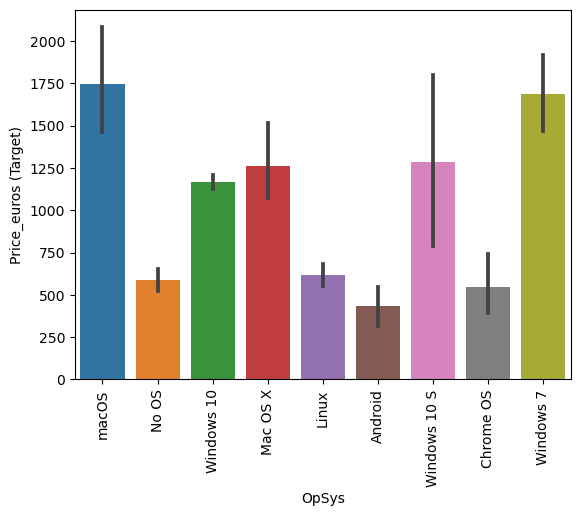

In [75]:
sns.barplot(x=df['OpSys'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [76]:
def cat_os(inp):
    if inp == 'Windows 10' or inp == 'Windows 7' or inp == 'Windows 10 S':
        return 'Windows'
    elif inp == 'macOS' or inp == 'Mac OS X':
        return 'Mac'
    else:
        return 'Others/No OS/Linux'

In [77]:
df['os']=df['OpSys'].apply(cat_os)

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\3255695950.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['os']=df['OpSys'].apply(cat_os)


In [78]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os
0,1,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128,Intel,Mac
1,2,Apple,Macbook Air,Ultrabook,8,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,3,HP,250 G6,Notebook,8,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,256,Intel,Others/No OS/Linux
3,4,Apple,MacBook Pro,Ultrabook,16,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512,AMD,Mac
4,5,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256,Intel,Mac


In [79]:
df.drop(columns=['OpSys'],inplace=True)

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\3105339334.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['OpSys'],inplace=True)


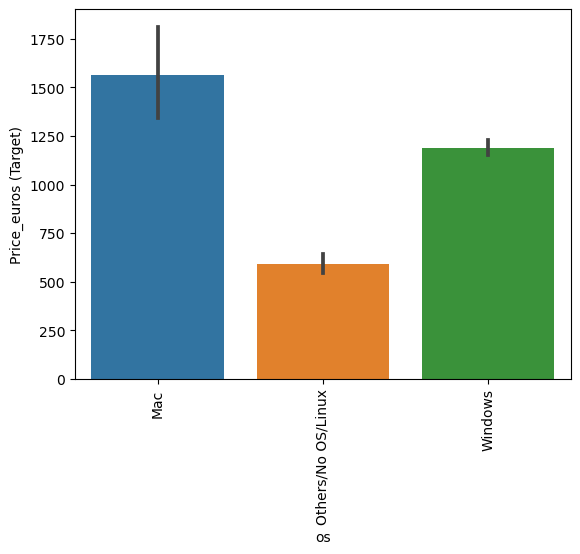

In [80]:
sns.barplot(x=df['os'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1125578356.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Weight'])


<Axes: xlabel='Weight', ylabel='Density'>

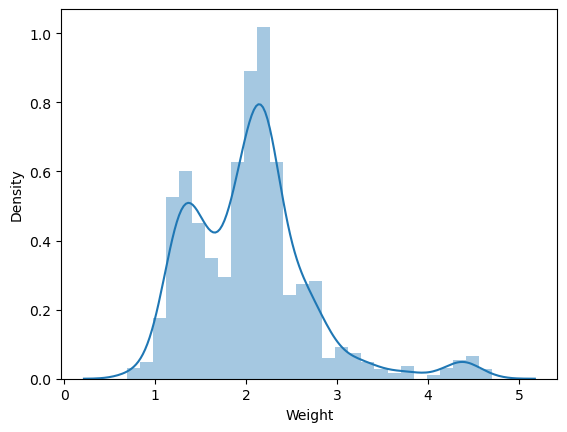

In [81]:
sns.distplot(df['Weight'])

<Axes: xlabel='Weight', ylabel='Price_euros (Target)'>

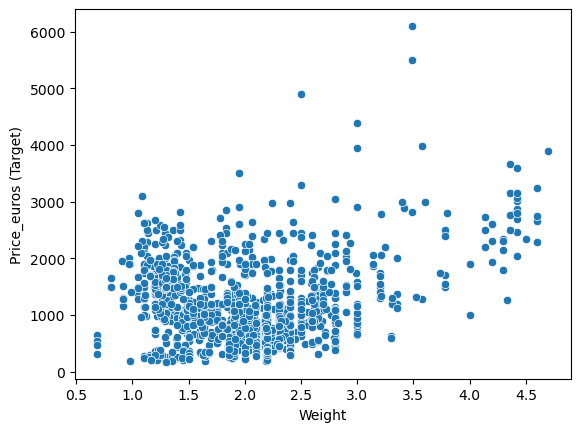

In [82]:
sns.scatterplot(x=df['Weight'],y=df['Price_euros (Target)'])

In [83]:
df.corr()['Price_euros (Target)']

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1672364737.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()['Price_euros (Target)']


laptop_ID               0.068632
Ram                     0.742905
Weight                  0.209867
Price_euros (Target)    1.000000
Touchscreen             0.192917
Ips                     0.253320
ppi                     0.475368
HDD                    -0.380836
SSD                     0.676066
Name: Price_euros (Target), dtype: float64

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\1093788652.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Price_euros (Target)'])


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

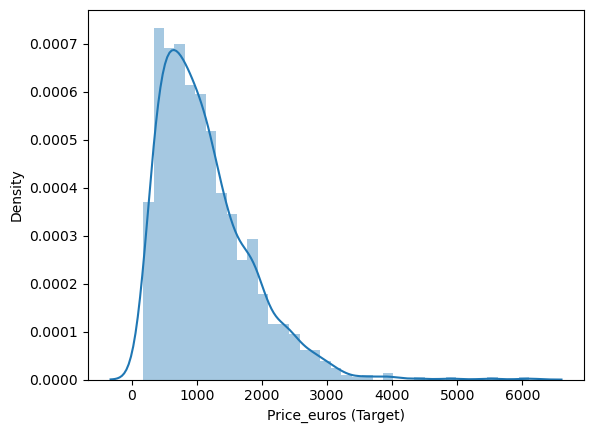

In [84]:
sns.distplot(df['Price_euros (Target)'])

C:\Users\ibrah\AppData\Local\Temp\ipykernel_19068\684539983.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log(df['Price_euros (Target)']))


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

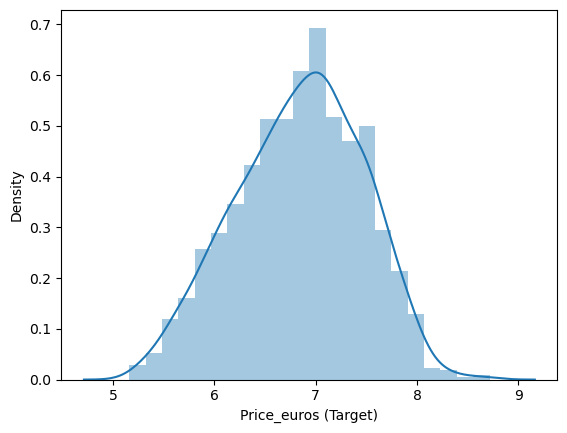

In [85]:
sns.distplot(np.log(df['Price_euros (Target)']))

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1302 entries, 0 to 1302
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1302 non-null   int64  
 1   Company               1302 non-null   object 
 2   Product               1302 non-null   object 
 3   TypeName              1302 non-null   object 
 4   Ram                   1302 non-null   int32  
 5   Weight                1302 non-null   float64
 6   Price_euros (Target)  1302 non-null   float64
 7   Touchscreen           1302 non-null   int64  
 8   Ips                   1302 non-null   int64  
 9   ppi                   1302 non-null   float64
 10  Cpu brand             1302 non-null   object 
 11  HDD                   1302 non-null   int64  
 12  SSD                   1302 non-null   int64  
 13  Gpu brand             1302 non-null   object 
 14  os                    1302 non-null   object 
dtypes: float64(3), int32(

In [87]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# Linear Regression:

In [88]:
X = df.drop(columns='Price_euros (Target)')  # Features
y = df['Price_euros (Target)']  # Target variable

# Identify categorical features
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# Evaluate the model
score = model.score(X_test, y_test)
print(f"Model R^2 score: {score}")
print(f"Mean Abs Error: {mean_absolute_error(y_test,y_pred)}")

Model R^2 score: 0.798677532978014
Mean Abs Error: 197.86647471962817


# KNN:

In [155]:
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=3))  # Use KNN instead of LinearRegression
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
score = model.score(X_test, y_test)  # R^2 score
print(f"Model R^2 score: {score}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")

Model R^2 score: 0.4047706017543852
Mean Absolute Error: 364.63102171136654


# Random Forest:

In [158]:
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))  # Use Random Forest
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
score = model.score(X_test, y_test)  # R^2 score
print(f"Model R^2 score: {score}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")

Model R^2 score: 0.8102245018097018
Mean Absolute Error: 193.7589295019157


In [166]:
import pandas as pd

# Example laptop specifications with all necessary columns
laptop_specs = {
    'laptop_ID': [1],  # Add a dummy ID
    'Company': ['Dell'],
    'Product': ['Inspiron'],
    'TypeName': ['Notebook'],
    'Ram': [8],
    'Weight': [2.5],
    'Touchscreen': [0],
    'Ips': [1],
    'ppi': [141.211998],
    'Cpu brand': ['Intel Core i5'],
    'HDD': [0],
    'SSD': [256],
    'Gpu brand': ['Intel'],
    'os': ['Windows']
}

# Convert the specifications to a DataFrame
input_data = pd.DataFrame(laptop_specs)

# Preprocess the input data
preprocessed_input = preprocessor.transform(input_data)

# Predict the price
predicted_price = model.predict(preprocessed_input)

print(f"Predicted Laptop Price: {predicted_price[0]}")


ValueError: X has 575 features, but ColumnTransformer is expecting 14 features as input.

In [161]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os
0,1,Apple,MacBook Pro,Ultrabook,8,1.37,1339.69,0,1,226.983005,Intel Core i5,0,128,Intel,Mac
1,2,Apple,Macbook Air,Ultrabook,8,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,3,HP,250 G6,Notebook,8,1.86,575.00,0,0,141.211998,Intel Core i5,0,256,Intel,Others/No OS/Linux
3,4,Apple,MacBook Pro,Ultrabook,16,1.83,2537.45,0,1,220.534624,Intel Core i7,0,512,AMD,Mac
4,5,Apple,MacBook Pro,Ultrabook,8,1.37,1803.60,0,1,226.983005,Intel Core i5,0,256,Intel,Mac
